# IND320 — Project Work, Part 4

**GitHub repository:** https://github.com/isach07/IND320_isachstevik

**Streamlit app:** https://ind320isachstevik-dsj69wxyp9oamezekyfwal.streamlit.app

**Video presentation:** https://www.youtube.com/watch?v=AASYFbpkZTM

**Git:** all new work is done on the `demo` branch, so `main` stays unchanged while the peer review and teacher feedback are going on. When the feedback is finished, `demo` is merged into `main`, and the Streamlit app updates from `main`.

## Table of contents

1. [Exchange rates from Norges Bank](#exchange-rates)
2. [Time zones in the data sources](#time-zones)
3. [Forecasting the reservoir filling with River](#forecast)
   - [Confidence intervals with quantile loss](#intervals)
4. [Sketches of the app](#sketches)
5. [Log](#log)
6. [AI usage](#ai-usage)

In [1]:
import requests
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

# interactive plots in the notebook, plus a static image so the plots are also shown in the PDF export
pio.renderers.default = "plotly_mimetype+png"

<a id="exchange-rates"></a>
## Exchange rates from Norges Bank

Norges Bank has an open API with daily exchange rates. The request asks for the price of one euro and one US dollar in Norwegian kroner, for each business day.

The answer comes as SDMX-JSON, where the values, dates and currency names are stored in separate lists. The function puts them together into one table with one row per date and one column per currency.

In [2]:
NB_URL = "https://data.norges-bank.no/api/data/EXR"


# dayly exchenge rates in NOK form NB
# currencies is EUR and USD.
#  start, end: dates as text, e.g. "2024-01-01" (both included), or None for no limit
# n_last, the last business days, e.g. 60
# return tabel
def download_exchange_rates(currencies=("EUR", "USD"), start=None, end=None, last_n=None):
    currencies = list(currencies)
    key = f"B.{'+'.join(currencies)}.NOK.SP"   # business days, currencies, in NOK, spot rate
    params = {"format": "sdmx-json", "locale": "en"}
    if start:
        params["startPeriod"] = start
    if end:
        params["endPeriod"] = end
    if last_n:
        params["lastNObservations"] = last_n

    resp = requests.get(f"{NB_URL}/{key}", params=params, timeout=30)
    if resp.status_code == 404:   # Norges Bank answers 404 when there is no data, e.g. a wrong currency code
        raise ValueError(f"No data from Norges Bank for {key} with {params}")
    resp.raise_for_status()
    data = resp.json()["data"]

    # the labels: which currency and which date each position stands for
    series_dimensions = data["structure"]["dimensions"]["series"]
    currency_position = [d["id"] for d in series_dimensions].index("BASE_CUR")
    currency_codes = [v["id"] for v in series_dimensions[currency_position]["values"]]
    dates = [v["id"] for v in data["structure"]["dimensions"]["observation"][0]["values"]]

    # the numbers: one series per currency, one observation per date
    rates = {}
    for series_key, series in data["dataSets"][0]["series"].items():
        currency = currency_codes[int(series_key.split(":")[currency_position])]
        rates[currency] = pd.Series({
            dates[int(date_position)]: float(value[0])   # values come as text
            for date_position, value in series["observations"].items()
        })

    table = pd.DataFrame(rates)
    table.index = pd.to_datetime(table.index)
    table.index.name = "date"
    return table.sort_index()[currencies]   # same column order as asked for

<a id="exchange-rates-test"></a>
### Showing that it works

First the request from the task: the latest 60 business days.

In [3]:
# the latest 60 business days for euro and dollar
rates = download_exchange_rates(last_n=60)
print(rates.shape)
rates.tail()

(60, 2)


,EUR,USD
date,,
2026-11-16,10.5740,9.6005
2026-11-17,10.5755,9.6237
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525


<a id="time-zones"></a>
## Time zones in the data sources

In this project I have 4 different sources of data, each with its own time zone and frequency:

- **Magasinstatistikk (NVE):** one value per ISO week, dated on the Sunday that ends the week. No time zone.
- **ENTSO-E:** hourly values in UTC. Summing them per UTC day would shift each day by 1–2 hours compared with the Norwegian calendar.
- **Open-Meteo:** GMT by default. With `timezone=Europe/Oslo` (used in part 3 and the app), daily values follow Norwegian days.
- **Norges Bank:** one rate per Norwegian business day, so weekends and holidays are missing.

There is no problem as long as each source is used alone. When they are combined, all of them should be put on the same clock: Norwegian calendar days, or ISO weeks ending on Sunday when comparing with the reservoir data. Here are 3 helper functions to do that.

In [4]:
# hourly values with UTC times (entso-e) -> one value per Norwegian calendar day
def utc_to_oslo_days(hourly, how="sum"):
    if hourly.index.tz is None:   # plain times are treated as UTC, as stored in part 2
        hourly = hourly.tz_localize("UTC")
    oslo = hourly.tz_convert("Europe/Oslo")
    daily = oslo.groupby(oslo.index.date).agg(how)
    daily.index = pd.to_datetime(daily.index)
    daily.index.name = "date"
    return daily

# rates on business days -> every calendar day, using the last known rate on weekends and holidays
def fill_business_days(rates):
    all_days = pd.date_range(rates.index.min(), rates.index.max(), freq="D", name="date")
    return rates.reindex(all_days).ffill()

# daily values -> ISO weeks (Monday-Sunday), dated on the Sunday like dato_Id in Magasinstatistikk
def to_nve_weeks(daily, how="mean"):
    return daily.resample("W-SUN").agg(how)

In [5]:
# 1) UTC hours around the summer time changes: the Norwegian days get 23 and 25 hours
hours_utc = pd.Series(1.0, index=pd.date_range("2025-03-29", "2025-11-01", freq="h"))
hours_per_day = utc_to_oslo_days(hours_utc)
print("Days that are not 24 hours long:")
print(hours_per_day[hours_per_day != 24].iloc[1:-1])   # first and last day are cut by the period

# 2) exchange rates on every calendar day, with no gaps
rates_daily = fill_business_days(rates)
assert rates_daily.notna().all().all()
assert (rates_daily.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all()
print(f"\nAdded {len(rates_daily) - len(rates)} weekend and holiday days to {len(rates)} business days")

# 3) weekly averages dated on Sundays, ready to join with the reservoir data
rates_weekly = to_nve_weeks(rates_daily)
assert (rates_weekly.index.dayofweek == 6).all()   # 6 = Sunday
rates_weekly.tail()

Days that are not 24 hours long:
date
2025-03-30    23.0
2025-10-26    25.0
dtype: float64

Added 22 weekend and holiday days to 60 business days


,EUR,USD
date,,
2026-10-25,10.497071,9.365429
2026-11-01,10.351143,9.275571
2026-11-08,10.443929,9.327429
2026-11-15,10.576286,9.519757
2026-11-22,10.623900,9.666380


<a id="forecast"></a>
## Forecasting the reservoir filling with River

The function `forecast_filling` in utils/forecast_utils.py forecasts the degree of filling for one region in Magasinstatistikk for the coming weeks. It uses SARIMAX from River (time_series.SNARIMAX), where the model learns online, one week at a time. SARIMAX is a seasonal ARIMA model, here with a seasonal period of 52 weeks, and the data sources are its exogenous variables.

Inputs: area, model parameters (p, d, q and the seasonal sp, sd, sq, plus the learning rate of the online linear regression River uses inside SNARIMAX), history length in years, horizon in weeks, and data sources.

Data sources:
- the filling itself (always used)
- weather: weekly precipitation, snowfall and mean temperature for the region, from ERA5 at 5 of the locations sampled in part 3
- exchange_rates: weekly EUR/NOK from Norges Bank

The future values of the sources are unknown, so the forecast uses the normal value for that week of the year (weather) or the last known value (exchange rate).

Time resolution: weekly. This is the resolution of Magasinstatistikk itself, and the daily sources are summed or averaged per week (weeks Monday–Sunday, dated on Sunday, see the time zone section). Test 1 below compares this with daily data.

In [6]:
import sys
import time
import numpy as np
sys.path.insert(0, "..")          # the project folder, where the utils folder is
from utils import forecast_utils as fu

AREA = "EL 3"
# all data for the tests, downloaded once: filling, weather (from the cache in No_sync) and exchange rates
data = fu.load_data(AREA, ("weather", "exchange_rates"), start="2003-01-05")

# 36 forecast origins, every 4 weeks over the last 3 years, each followed by 13 known weeks
last = data.index.max()
origins = pd.date_range(last - pd.Timedelta(weeks=13 + 4 * 35), last - pd.Timedelta(weeks=13), freq="4W-SUN")
print(data.shape, f"origins: {origins[0].date()} to {origins[-1].date()}")
data.tail(3)

(1246, 5) origins: 2023-12-10 to 2026-08-16


,filling,eur_nok,precipitation,snowfall,temperature
date,,,,,
2026-11-01,72.01489,10.351143,44.68,1.540,4.820000
2026-11-08,71.87052,10.443929,5.96,0.028,1.945714
2026-11-15,69.72779,10.576286,50.22,20.874,-0.840000


### A forecast with the default settings

The default settings are the best ones from the tests below. The plot shows the last three years and the forecast for the next 13 weeks (about 3 months).

{'model_params': {'p': 1, 'd': 1, 'q': 0, 'sp': 0, 'sd': 1, 'sq': 1, 'learning_rate': 0.003}, 'history_years': 20, 'horizon_weeks': 13, 'sources': ()}
Time used: 0.021 s


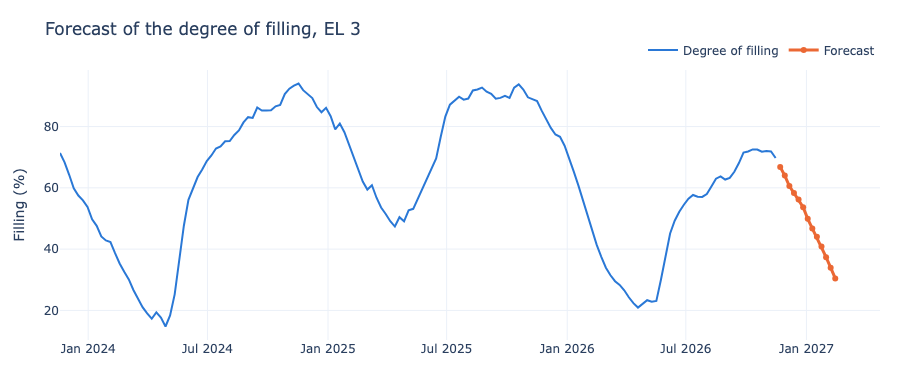

date,2026-11-22,2026-11-29,2026-12-06,2026-12-13,2026-12-20,2026-12-27,2027-01-03,2027-01-10,2027-01-17,2027-01-24,2027-01-31,2027-02-07,2027-02-14
forecast,66.8,64.0,60.6,58.3,56.2,53.7,49.9,46.8,44.1,40.9,37.4,34.0,30.4


In [7]:
print(fu.DEFAULTS)
t0 = time.perf_counter()
forecast = fu.forecast_filling(AREA, data=data, **{k: v for k, v in fu.DEFAULTS.items()})
print(f"Time used: {time.perf_counter() - t0:.3f} s")

recent = data["filling"].loc[last - pd.DateOffset(years=3):]
fig = go.Figure()
fig.add_scatter(x=recent.index, y=recent, name="Degree of filling", line=dict(color="#2a78d6", width=2))
fig.add_scatter(x=forecast.index, y=forecast["forecast"], name="Forecast", line=dict(color="#eb6834", width=3))
fig.update_layout(title=f"Forecast of the degree of filling, {AREA}", yaxis_title="Filling (%)",
                  template="plotly_white", width=900, height=380, hovermode="x unified",
                  margin=dict(l=60, r=20, t=70, b=40),
                  legend=dict(orientation="h", y=1.02, x=1, xanchor="right", yanchor="bottom"))
fig.update_traces(hovertemplate="%{y:.1f} %")
fig.show()
forecast.round(1).T

### Finding the best settings

Each setting is tested on the past: from each of the 36 origins, the model learns from the history up to that week only, forecasts 13 weeks ahead, and the forecast is compared with what really happened. The score is the mean absolute error (MAE) in percentage points over all origins and all 13 weeks. Two simple forecasts are used as baselines:

- **last value:** the filling stays where it is
- **last year's change:** the filling changes like it did the same weeks last year

A model is only useful if it beats these.

In [8]:
# runs a list of settings through the backtest and collects the results in a table
def test_settings(settings, data=data, origins=origins):
    rows = []
    for name, s in settings.items():
        r = fu.backtest(data, origins, horizon_weeks=13, **s)
        rows.append({"setting": name, "mae": r["mae"], "mae_week_1": r["mae_by_step"][0],
                     "mae_week_13": r["mae_by_step"][-1], "seconds": r["seconds"]})
    return pd.DataFrame(rows).set_index("setting").sort_values("mae").round(2)

baselines = fu.baseline_forecasts(data, origins)
pd.DataFrame({k: {"mae": v["mae"], "mae_week_1": v["mae_by_step"][0], "mae_week_13": v["mae_by_step"][-1]}
              for k, v in baselines.items()}).T.round(2)

,mae,mae_week_1,mae_week_13
last value,14.45,2.60,24.77
last year's change,7.04,2.01,10.53


### Time resolution

Magasinstatistikk only has one value per week. A daily model would need daily filling values, made by drawing straight lines between the weekly values. The test runs the same SARIMAX model at weekly resolution (seasonal period 52 weeks, 13 weeks ahead) and at daily resolution (seasonal period 365 days, 91 days ahead), both scored on the weekly values.

In [9]:
from river import linear_model, optim, preprocessing, time_series

weekly = data["filling"]
daily = weekly.resample("D").interpolate()   # straight lines between the weekly values

# the default SARIMAX from forecast_utils, but with one step per day
def daily_sarimax(origin, horizon_days=91, history_years=20):
    hist = daily.loc[origin - pd.DateOffset(years=history_years):origin]
    regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(optimizer=optim.SGD(0.003))
    model = time_series.SNARIMAX(p=1, d=1, q=0, m=365, sp=0, sd=1, sq=1, regressor=regressor)
    for y in hist:
        model.learn_one(y)
    dates = pd.date_range(origin + pd.Timedelta(days=1), periods=horizon_days, freq="D")
    return pd.Series(np.clip(model.forecast(horizon_days), 0, 100), index=dates)

rows = []
for name, run in [("weekly", lambda o: fu.forecast_filling(data=data, end=o, horizon_weeks=13)["forecast"]),
                  ("daily", daily_sarimax)]:
    t0, errors = time.perf_counter(), []
    for o in origins:
        sundays = pd.date_range(o + pd.Timedelta(weeks=1), periods=13, freq="W-SUN")
        errors.append(np.abs(run(o).reindex(sundays).values - weekly.reindex(sundays).values))
    rows.append({"resolution": name, "mae": np.nanmean(errors), "seconds_36_forecasts": time.perf_counter() - t0})
pd.DataFrame(rows).set_index("resolution").round(3)

,mae,seconds_36_forecasts
resolution,,
weekly,5.939,0.680
daily,8.341,1.173


### Model parameters

All without extra data sources and with 10 years of history, so only the model parameters change: the AR order p, differencing d, the seasonal AR, differencing and MA orders sp, sd, sq, and the learning rate. A few models without seasonal differencing (sd = 0) are included to see if it matters.

In [10]:
import itertools

settings = {}
for p_, d_, sp_, sq_, lr in itertools.product([1, 2, 3], [0, 1], [0, 1], [0, 1], [0.01, 0.003, 0.001]):
    settings[f"({p_},{d_},0)({sp_},1,{sq_})52, lr {lr}"] = dict(
        model_params=dict(p=p_, d=d_, q=0, sp=sp_, sd=1, sq=sq_, learning_rate=lr), history_years=10, sources=())
for p_, sp_, sq_ in [(1, 0, 0), (2, 1, 1)]:
    settings[f"({p_},0,0)({sp_},0,{sq_})52, lr 0.003"] = dict(
        model_params=dict(p=p_, d=0, q=0, sp=sp_, sd=0, sq=sq_, learning_rate=0.003), history_years=10, sources=())
results_models = test_settings(settings)
print(f"{len(results_models)} settings, the best 10 and the worst 5:")
pd.concat([results_models.head(10), results_models.tail(5)])

74 settings, the best 10 and the worst 5:


,mae,mae_week_1,mae_week_13,seconds
setting,,,,
"(3,0,0)(0,1,1)52, lr 0.003",5.83,2.16,7.71,0.38
"(2,0,0)(0,1,1)52, lr 0.003",5.91,2.03,7.82,0.36
"(1,1,0)(0,1,1)52, lr 0.003",6.12,1.35,9.35,0.36
"(3,0,0)(1,1,0)52, lr 0.003",6.13,2.43,7.94,0.42
"(2,1,0)(0,1,1)52, lr 0.003",6.17,1.36,9.49,0.36
"(3,0,0)(1,1,1)52, lr 0.003",6.18,2.22,8.13,0.39
"(2,1,0)(0,1,1)52, lr 0.001",6.25,1.62,9.28,0.36
"(2,1,0)(1,1,1)52, lr 0.001",6.26,1.56,9.38,0.38
"(1,1,0)(1,1,1)52, lr 0.001",6.26,1.57,9.30,0.38


### Length of history and data sources

The two best orders from test 2 with 5, 10 and 20 years of history, and with each combination of data sources.

In [11]:
settings = {}
for order in [dict(p=1, d=1, q=0, sp=0, sd=1, sq=1), dict(p=2, d=0, q=0, sp=0, sd=1, sq=1)]:
    name = f"({order['p']},{order['d']},0)(0,1,1)52"
    for history in [5, 10, 20]:
        for sources in [(), ("weather",), ("exchange_rates",), ("weather", "exchange_rates")]:
            settings[f"{name}, {history} years, {' + '.join(sources) or 'filling only'}"] = dict(
                model_params={**order, "learning_rate": 0.003}, history_years=history, sources=sources)
results_sources = test_settings(settings)
results_sources

,mae,mae_week_1,mae_week_13,seconds
setting,,,,
"(2,0,0)(0,1,1)52, 20 years, filling only",5.28,1.76,7.20,0.73
"(1,1,0)(0,1,1)52, 20 years, exchange_rates",5.90,1.14,9.22,0.72
"(2,0,0)(0,1,1)52, 10 years, filling only",5.91,2.03,7.82,0.37
"(1,1,0)(0,1,1)52, 20 years, filling only",5.94,1.14,9.53,0.67
"(1,1,0)(0,1,1)52, 10 years, filling only",6.12,1.35,9.35,0.36
"(1,1,0)(0,1,1)52, 5 years, filling only",6.37,1.65,9.51,0.20
"(1,1,0)(0,1,1)52, 10 years, exchange_rates",6.40,1.38,9.82,0.39
"(1,1,0)(0,1,1)52, 5 years, exchange_rates",6.51,1.64,9.74,0.22
"(2,0,0)(0,1,1)52, 10 years, exchange_rates",6.55,2.09,9.17,0.41


### The other regions

The best settings from test 3 (filling only, since the weather history is only downloaded for EL 3 to save API calls), tested in every region against the baselines.

In [12]:
candidates = {
    f"({p_},{d_},0)(0,1,1)52, {h} years": dict(model_params=dict(p=p_, d=d_, q=0, sp=0, sd=1, sq=1, learning_rate=0.003),
                                              history_years=h, sources=())
    for p_, d_ in [(1, 1), (2, 0), (3, 0)] for h in [10, 20]
}
rows = []
for area in ["NO 0", "EL 1", "EL 2", "EL 3", "EL 4", "EL 5", "VASS 1", "VASS 2", "VASS 3"]:
    area_data = fu.load_data(area)
    area_last = area_data.index.max()
    area_origins = pd.date_range(area_last - pd.Timedelta(weeks=13 + 4 * 35), area_last - pd.Timedelta(weeks=13), freq="4W-SUN")
    row = {"area": area, **{k: v["mae"] for k, v in fu.baseline_forecasts(area_data, area_origins).items()}}
    for name, s in candidates.items():
        row[name] = fu.backtest(area_data, area_origins, **s)["mae"]
    rows.append(row)
results_regions = pd.DataFrame(rows).set_index("area")
results_regions.loc["mean"] = results_regions.mean()
results_regions.round(2).T

area,NO 0,EL 1,EL 2,EL 3,EL 4,EL 5,VASS 1,VASS 2,VASS 3,mean
last value,11.58,17.52,9.25,14.45,9.90,16.75,13.19,11.22,10.85,12.74
last year's change,5.05,7.20,5.88,7.04,5.75,5.93,6.88,5.50,5.64,6.10
"(1,1,0)(0,1,1)52, 10 years",4.06,5.47,5.10,6.12,4.58,5.33,5.68,4.92,4.60,5.09
"(1,1,0)(0,1,1)52, 20 years",3.74,5.03,4.49,5.94,4.28,4.81,4.88,4.46,4.32,4.66
"(2,0,0)(0,1,1)52, 10 years",4.57,6.80,6.36,5.91,4.10,5.00,7.19,4.83,4.19,5.44
"(2,0,0)(0,1,1)52, 20 years",3.94,5.81,5.39,5.28,3.75,4.57,5.73,4.66,3.71,4.76
"(3,0,0)(0,1,1)52, 10 years",4.61,6.87,6.18,5.83,4.28,5.11,7.20,4.91,4.36,5.48
"(3,0,0)(0,1,1)52, 20 years",3.98,5.86,5.46,5.65,3.92,4.59,5.87,4.81,3.87,4.89


So now I have done 4 different tests, and the best model is the one with (1,1,0)(0,1,1)52 and 20 years of history, learning rate 0.003 and a 13 week horizon. The best model is without extra information from weather and exchange rates.


## Bonus task
Quantile loss is a way of training the model to aim low or high on purpose. It learns a low guess, a high guess and a middle guess. I tried three ways of making the band:

- **Quantile, own forecasts:** the low and high models forecast all 13 weeks on their own.
- **Quantile, widened:** the low and high models are only used for the first week, then the band grows with a fixed rule.
- **Past errors:** no quantile loss. It is based on the previous errors and makes a band that is just wide enough to hold most of those mistakes.


In [13]:
methods = {
    "Quantile, own forecasts": lambda d, s, o: fu.quantile_bands(d, s, o, 13, growth=None),
    "Quantile, widened": lambda d, s, o: fu.quantile_bands(d, s, o, 13),
    "Past errors": lambda d, s, o: fu.error_bands(d, s, o, 13, levels=(0.8, 0.9))[0],
}
rows = []
for area in ["EL 3", "NO 0", "EL 1", "VASS 2"]:
    area_data = fu.load_data(area)
    area_last = area_data.index.max()
    area_origins = pd.date_range(area_last - pd.Timedelta(weeks=13 + 4 * 35), area_last - pd.Timedelta(weeks=13), freq="4W-SUN")
    inside = {(m, l): [] for m in methods for l in (0.8, 0.9)}
    width = {(m, l): [] for m in methods for l in (0.8, 0.9)}
    for origin in area_origins:
        start = origin - pd.DateOffset(years=20)
        fc = fu.forecast_window(area_data, start, origin, 13).values
        actual = area_data["filling"].reindex(pd.date_range(origin + pd.Timedelta(weeks=1), periods=13, freq="W-SUN")).values
        for name, make in methods.items():
            for level, (lo, hi) in make(area_data, start, origin).items():
                inside[name, level].append((actual >= fc + lo) & (actual <= fc + hi))
                width[name, level].append(hi - lo)
    for (name, level), values in inside.items():
        values, w = np.array(values), np.array(width[name, level])
        rows.append({"area": area, "method": name, "level": f"{level:.0%}", "coverage": values.mean(),
                     "coverage_week_1": values[:, 0].mean(), "coverage_week_13": values[:, -1].mean(),
                     "width_week_1": w[:, 0].mean(), "width_week_13": w[:, -1].mean()})
intervals = pd.DataFrame(rows)
summary = intervals.groupby(["method", "level"]).mean(numeric_only=True)
summary.style.format({c: "{:.0%}" for c in summary.columns if c.startswith("coverage")} |
                     {c: "{:.1f}" for c in summary.columns if c.startswith("width")})

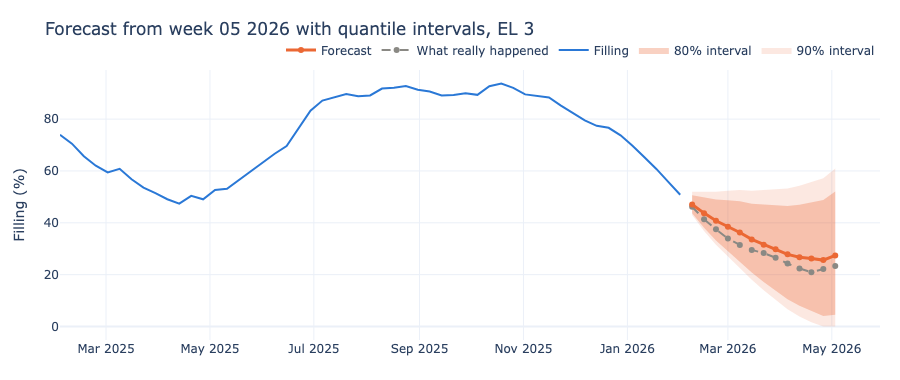

In [14]:
# an example: the forecast from one week in the past, with the quantile bands and what really happened
origin = origins[-8]
start = origin - pd.DateOffset(years=20)
fc = fu.forecast_window(data, start, origin, 13)
bands = fu.quantile_bands(data, start, origin, 13)
past = data["filling"].loc[origin - pd.DateOffset(years=1):origin]
actual = data["filling"].reindex(fc.index)

fig = go.Figure()
for level, opacity in [(0.9, 0.15), (0.8, 0.3)]:
    lo, hi = bands[level]
    fig.add_scatter(x=fc.index, y=(fc + hi).clip(upper=100), mode="lines", line=dict(width=0), showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=fc.index, y=(fc + lo).clip(lower=0), mode="lines", line=dict(width=0), fill="tonexty",
                    fillcolor=f"rgba(235,104,52,{opacity})", name=f"{level:.0%} interval", hoverinfo="skip")
fig.add_scatter(x=past.index, y=past, name="Filling", line=dict(color="#2a78d6", width=2))
fig.add_scatter(x=actual.index, y=actual, name="What really happened", line=dict(color="#8a8984", width=2, dash="dash"))
fig.add_scatter(x=fc.index, y=fc, name="Forecast", line=dict(color="#eb6834", width=3))
fig.update_layout(title=f"Forecast from week {origin:%V} {origin:%G} with quantile intervals, {AREA}", yaxis_title="Filling (%)",
                  template="plotly_white", width=900, height=380, hovermode="x unified", margin=dict(l=60, r=20, t=70, b=40),
                  legend=dict(orientation="h", y=1.02, x=1, xanchor="right", yanchor="bottom"))
fig.update_traces(hovertemplate="%{y:.1f} %")
fig.show()

#### Findings on the confidence intervals

| Method | 80 % band covers | 90 % band covers | 90 % width after 13 weeks |
|---|---|---|---|
| Quantile, own forecasts | 94 % | 98 % | 83 pp |
| Quantile, widened | 78 % | 89 % | 55 pp |
| Past errors | 77 % | 86 % | 30 pp |

- **Own forecasts:** almost always right, but only because the band is far too wide to be useful.
- **Widened:** the most honest, close to 80 % and 90 %. This is the default in the app.
- **Past errors:** narrower, but misses a bit too often.
- After 3 months the real filling can be 15–25 pp away from the forecast.

In [15]:
# the function stops with a clear message on wrong inputs
for bad in [dict(model_params={"order": 3}), dict(sources=("rain",)), dict(area="EL 9")]:
    try:
        fu.forecast_filling(**{"area": AREA, "sources": (), **bad})
    except ValueError as error:
        print(f"{bad}: {error}")

{'model_params': {'order': 3}}: Unknown model parameters: {'order'}. Choose from ('p', 'd', 'q', 'sp', 'sd', 'sq', 'learning_rate')
{'sources': ('rain',)}: Unknown data sources: {'rain'}. Choose from ('weather', 'exchange_rates')
{'area': 'EL 9'}: Unknown area: EL 9


<a id="sketches"></a>
## Sketches of the app

Before building the new pages, I sketched the design on paper.

**The dashboard:** the menu on the left, the home page with the animation, the context text and the key numbers, the forecast with its settings and the future part of the curve, the outliers and anomalies with a table of the points, and where the data comes from.

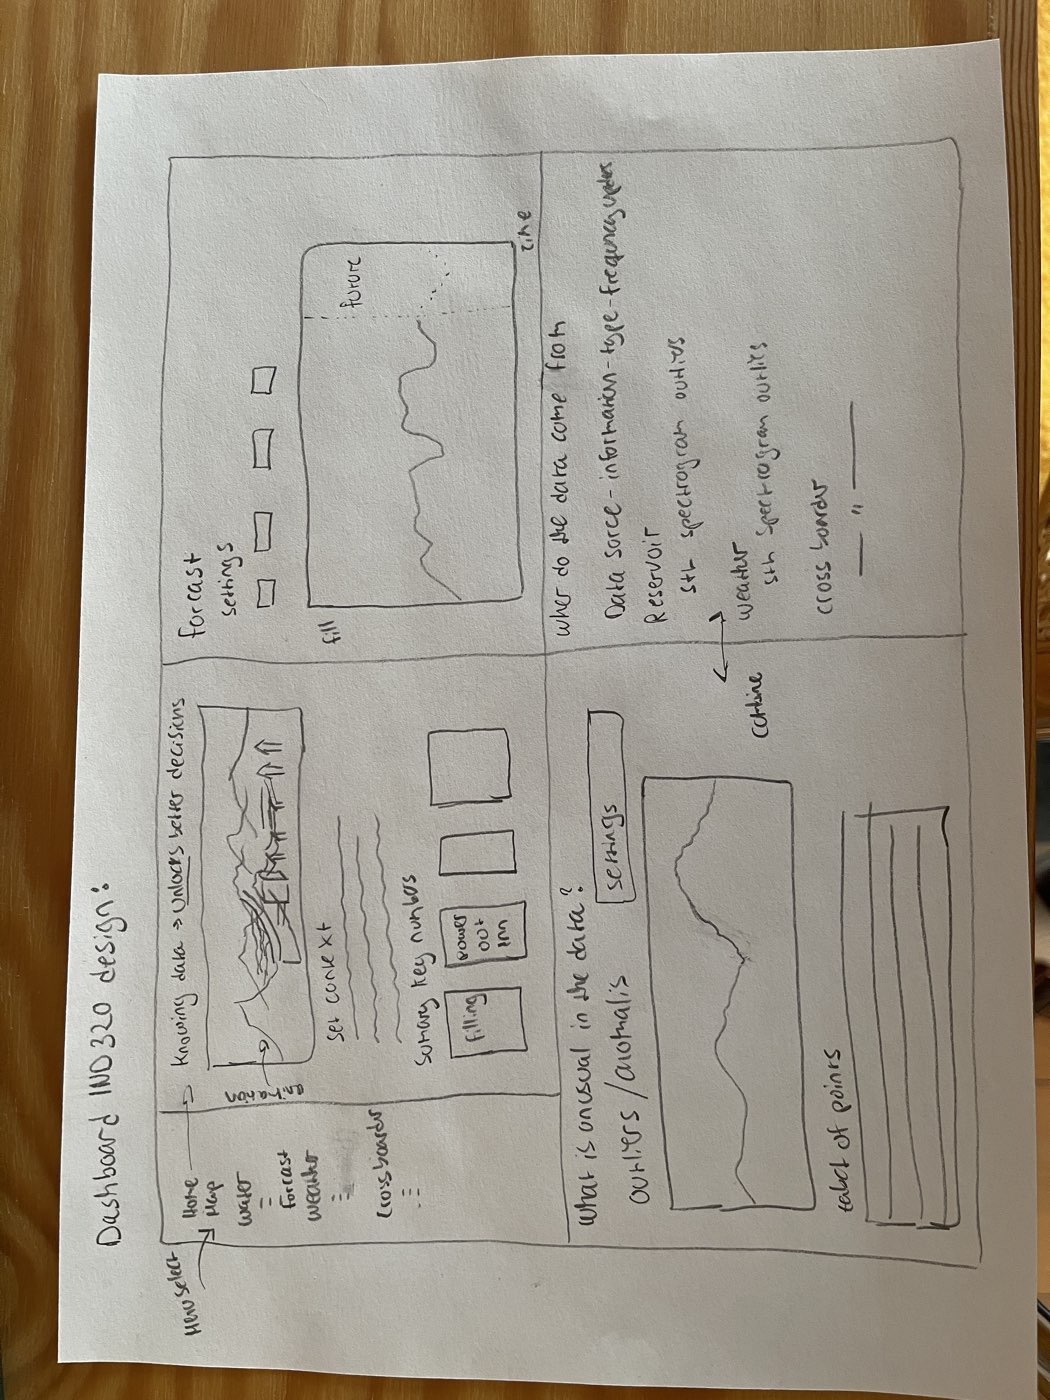

**The explore data pages** for reservoirs, weather and power flow: one page per source with tabs for the raw data, STL and spectrogram, outliers, and correlation.

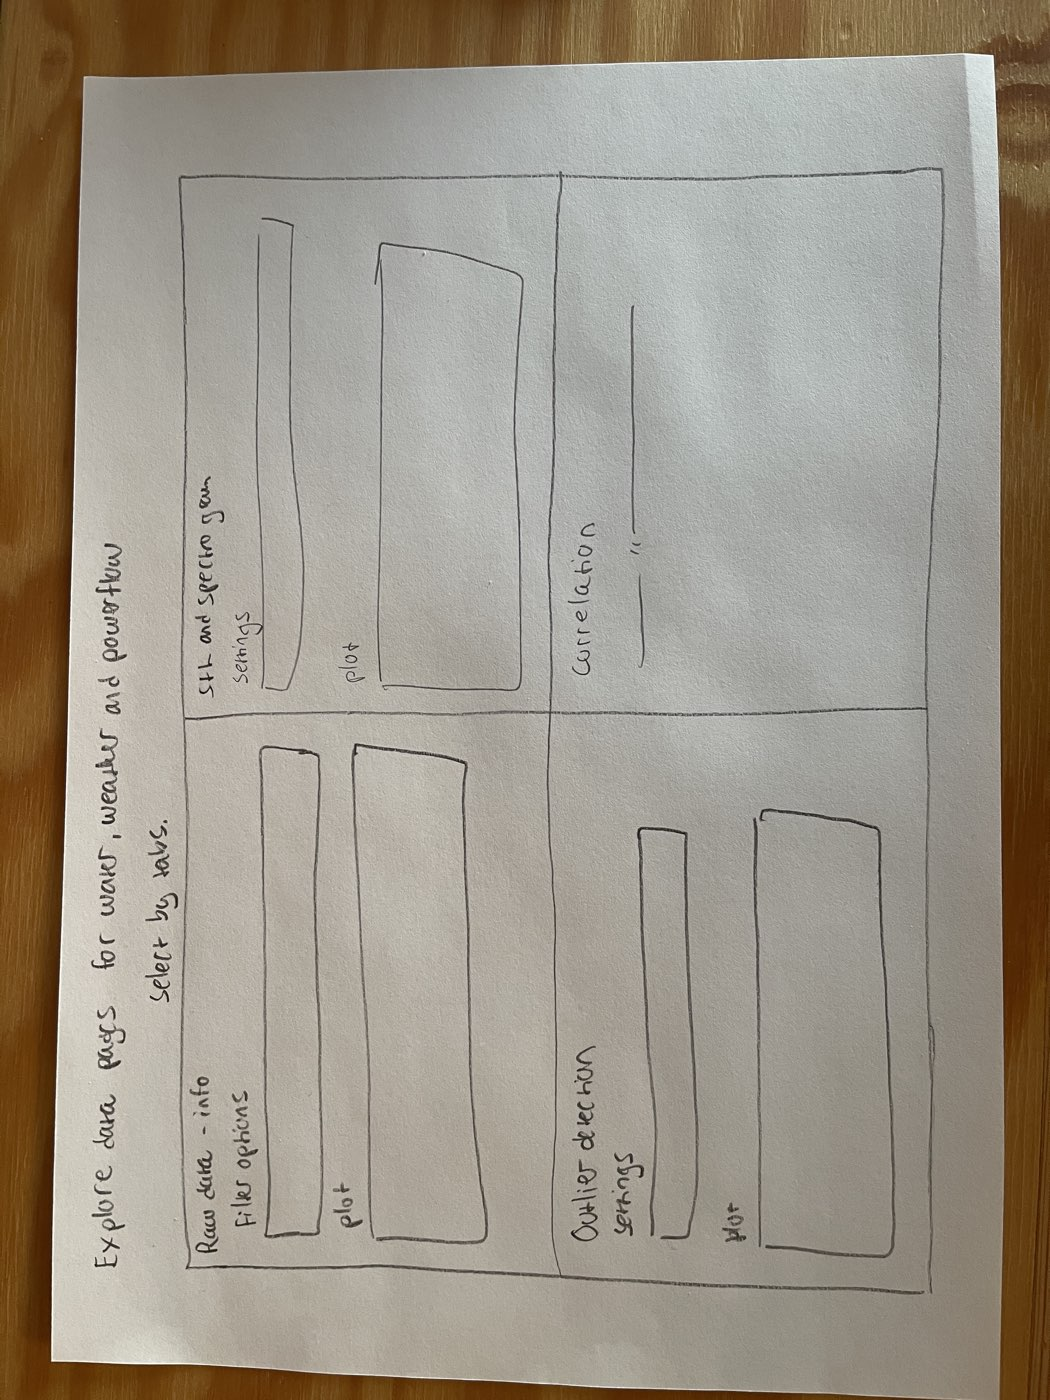

### Findings from the sliding window correlation 

I tested EL 3 for 2021 to 2026, mostly with the weekly change in fill ratio as the Magasinstatistikk variable, because the weather changes the filling and not the level directly.

- **Temperature** has the strongest link: r = 0.69 with lag 0, falling to 0.39 at 4 weeks and 0.14 at 8 weeks. With a 26 week window it is about 0.75–0.8 from winter to spring (warm weeks mean snowmelt and less power usage), but it drops every summer, and with an 8 week window it turns negative in July–September.
- **Rain** works mostly in the same week: r = 0.51 at lag 0, but only 0.12 at lag 2. It is strong in autumn and winter (about 0.8) and weak in June (about 0.1), when the snowmelt decides the filling.
- **Snowfall** changes sign with the season (positive in winter, negative in spring), so one fixed correlation does not describe it.
- **The fill ratio itself** correlates best with temperature about 11 weeks earlier (r = 0.76), but this is mostly the shared yearly cycle: the 26 week window swings from −0.77 to 0.90.

**For predictions:** the useful weather effects are short (0–2 weeks) and depend on the season. Weather from more than a few weeks back says little about the coming weeks, which fits the forecast tests above, where adding the weather made the SARIMAX forecast worse (5.2 to 6.9 for EL 3). A model that uses the weather should let the effect depend on the season, for example with separate summer and winter terms.

<a id="log"></a>
## Log

I started with setting up the new notebook. Then I went to the Norges Bank API to get the exchange rates. I wrote a function to parse the SDMX-JSON and put it into a table. Then I tested it with the last 60 business days, and it worked.

We have many different data sources with different time zones. They need to be on the same clock if we want to combine them. NVE has only weekly data, ENTSO-E has hourly data in UTC, Open-Meteo has daily data in GMT, and Norges Bank has daily data on business days. I wrote some helper functions to put them all on the same clock: Norwegian calendar days, or ISO weeks ending on Sunday when comparing with the reservoir data.

Then I started to work on the forecast function. I used SARIMAX from River, with online learning, meaning that the model learns one data point at a time and updates itself after each one, instead of looking at all the data at once. I tested different settings: time resolution, model parameters, length of history and data sources, and the other regions. I found that weekly resolution is better than daily, seasonal differencing is essential, more history improves the model, and adding weather or exchange rates made the forecasts worse. The best settings are SARIMAX (1,1,0)(0,1,1)52 with learning rate 0.003, 20 years of history, 13 weeks ahead, and the filling only as data source. I also looked at the sliding window correlation between the fill ratio and temperature, rain and snowfall. Temperature has the strongest link with lag 0, rain works mostly in the same week, and snowfall changes sign with the season. For predictions, useful weather effects are short (0–2 weeks) and depend on the season.

Then I implemented the new functions in the Streamlit app: a map with a GeoJSON-based overlay, where I put in the selection of price area, water area and weather properties. Then I updated the SATV and LOF plots with weather property selection. Then I created a correlation page where we can see the relationship between weather properties and the reservoir data, and lastly I created a forecast page where we can see the forecast for the next 13 weeks with confidence intervals.

When all the features were added, I made a plan of how I wanted the site to look. I sketched it out on a piece of paper and used that as a guide when I implemented the new layout. I also added an animation on the front page and a waterfall transition when clicking on the button linked to the forecast page. I decided to have Home, Map and Forecast as main pages, and exploration of the data for the different sources.

For the bonus task I implemented the quantile loss and made a test to see how well it worked. I found that the widened quantile band was the most honest, close to 80 % and 90 %.


<a id="ai-usage"></a>
## AI usage

I used AI (Claude) to generate and look at code, and to fix errors and bugs. In this last part I used AI to help me handle the new Norges Bank API and to create the helper functions for the time difference problem. I used it to create the test to find the optimal SARIMAX model parameters.

In the app I used it to implement the calculations for all the different pages and to restructure the layout according to the sketch. I also used it to generate the animation on the front page and the waterfall effect.
